<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/05_Malware_Detection/QSVM_MalwareClassification_Akter2023.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# QSVM for Android malware classification: Akter et al. (2023) step by step

**Paper.** Mst Shapna Akter, Hossain Shahriar, Kishor Datta Gupta, Muhammad Rahman, Sheikh Iqbal Ahamed, Atef Mohamed, Mohammad Rahman, Akond Rahman, Fan Wu, *Case Study-Based Approach of Quantum Machine Learning in Cybersecurity: Quantum Support Vector Machine for Malware Classification and Protection*, arXiv:2306.00284 (2023), a short education paper about one of ten Colab lab modules (Module 1, "Malware Classification Using Quantum Support Vector Machine"). Link: [arxiv.org/abs/2306.00284](https://arxiv.org/abs/2306.00284).

**What this notebook does.** The paper describes a teaching lab: students load the *drebin215* malware table, preprocess it, feed it to a quantum support vector machine (QSVM) written in PennyLane, and read off accuracy, precision, recall and F1. The only experimental result printed in the paper is one sentence in the abstract: *"We demonstrate our QSVM model and achieve an accuracy of 95% in malware classification and protection."* This notebook rebuilds that lab on the same public data: it downloads Drebin-215, reduces it to a few features, encodes them with a quantum feature map, builds the quantum kernel (Qiskit `FidelityStatevectorKernel` + `QSVC`, checked by hand and against a PennyLane circuit, since the paper uses PennyLane), trains the SVM on that kernel, compares it with classical SVMs and a random forest on identical inputs, and checks the 95% claim.

**How to run.** Open in Google Colab, CPU runtime, *Runtime -> Run all*. With `FAST_MODE = True` the notebook takes roughly 10 minutes; with `FAST_MODE = False` it uses the larger budgets listed in the configuration cell (see the note on the stored run in section 11). No account, token or upload is needed: the dataset is public (figshare).

**What you get at the end.** The data explained and plotted, the executed feature map drawn, the kernel verified three ways, confusion matrices, a qubit-count sweep with mean +/- std over seeds, and an explicit verdict (reproduced / not reached / cannot be checked) for each claim of the paper.

## The paper in one page

| Item | What the paper says |
|---|---|
| Problem | Classify software as malware or benign; teach students how a QSVM does it ("malware classification and protection"). |
| Setting | Case-study based learning: a *pre-lab*, a *hands-on lab* and a *post-lab* in Google Colab; ten planned modules (M1 is this QSVM malware module). A survey of 16 undergraduate students rates the labware. |
| Data | **drebin215**: the 215-attribute Android malware table of Yerima (figshare, "Android malware dataset for machine learning 2"). The user clicks "Choose File" and uploads the CSV. |
| Pipeline | load data -> preprocess -> feed to an SVM whose kernel is evaluated "in the quantum circuit" (PennyLane) -> accuracy, precision, recall, F1. |
| Claim | **QSVM accuracy of 95%** on malware classification (abstract). No table, figure, split, qubit count, feature map or hyper-parameter is given. |
| Student survey | Questionnaire answers of 16 students (Figures 4 to 11). Not a computational experiment and not repeatable here. |

Because the paper is silent on almost every design decision, this notebook has to choose them. They are collected in the table below and marked `# CHOICE:` in the code.

### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Dataset | drebin215 (Yerima, figshare), 215 attributes | Same file, downloaded from figshare (15,036 apps, 215 binary features, labels `S` = malware, `B` = benign). Five rows with a `?` value are dropped. Duplicate rows are kept (the paper does not remove them); their effect is measured in section 9 |
| Framework | PennyLane | Qiskit (`FidelityStatevectorKernel`, `QSVC`) for the main experiments, as in this repository's other QSVM notebooks, **plus** a PennyLane circuit of the same feature map whose kernel is asserted equal to Qiskit's (section 6) |
| Sample size | not stated (whole dataset?) | Balanced random sample of `N_SAMPLES` apps (half malware, half benign): a state-vector simulator cannot take 15,000 apps comfortably, and a balanced sample avoids the 63% benign majority |
| Train/test split | not stated | stratified 70/30 split, fresh draw for each seed |
| Preprocessing | "preprocessed the dataset" | `SelectKBest(f_classif)` -> `StandardScaler` -> `PCA(n_qubits)` -> `MinMaxScaler((0, pi))`, test angles clipped to [0, pi]; **every transform fitted on the training split only** |
| Number of qubits | not stated | 8 qubits (one PCA component per qubit), fixed before looking at any test result; 4, 6 and 10 qubits are reported as a sensitivity study |
| Feature map | not stated | Qiskit `zz_feature_map(reps=2, entanglement="linear")` |
| Kernel | quantum kernel (not stated which) | fidelity kernel `k(a, b) = |<phi(a)|phi(b)>|^2`, exact state-vector simulation |
| Bandwidth | not mentioned | angle scale chosen from `[1, 0.5, 0.25, 0.1]` on a validation split cut from the training data only |
| SVM hyper-parameters | not stated | `C = 1` for every SVM |
| Metrics | accuracy, precision, recall, F1 | the same four, malware is the positive class |
| Classical baselines | none in the paper | SVC (linear, RBF) and random forest on the identical angles; RBF-SVC and random forest also on all 215 features |
| Student survey | 16 students | cannot be reproduced |

In [1]:
# Installs pinned to the versions this notebook was tested with. Colab already ships numpy, pandas, scikit-learn, matplotlib.
# A runtime restart may be requested after the first install; run the cell again if so.
import importlib, sys
IN_COLAB = "google.colab" in sys.modules
def _have(mod):
    try:
        importlib.import_module(mod); return True
    except Exception:
        return False
if IN_COLAB or not (_have("qiskit") and _have("qiskit_machine_learning") and _have("pennylane")):
    !pip -q install "qiskit==2.5.2" "qiskit-machine-learning==0.9.1" "qiskit-aer==0.17.2" "pennylane==0.45.1" pylatexenc requests

In [2]:
# ---------------- Configuration: every tunable constant lives here ----------------
SEED = 42
FAST_MODE = False          # True: class demo, about 10 minutes. False: larger budgets (about 30 to 60 minutes on a CPU)

N_QUBITS = 8                # CHOICE: the paper does not give it; one PCA component per qubit
N_SAMPLES = 800 if FAST_MODE else 3000          # CHOICE: balanced sample (half malware, half benign) drawn from the 15,031 usable apps
TEST_SIZE = 0.30            # CHOICE: stratified 70/30 split
K_FEATURES = 100            # CHOICE: SelectKBest keeps this many of the 215 binary features before PCA
N_SEEDS = 2 if FAST_MODE else 5                 # repeated random draws for mean +/- std
QUBIT_SWEEP = [4, 8] if FAST_MODE else [4, 6, 8, 10]    # qubit counts of the sensitivity study (N_QUBITS must be in the list)
FM_REPS = 2                 # CHOICE: feature-map depth (the paper gives no circuit)
ENTANGLEMENT = "linear"     # CHOICE
BANDWIDTH_CHOICES = [1.0, 0.5, 0.25, 0.1]       # angle scales tried on a validation split (training data only)
C_SVM = 1.0                 # CHOICE: the paper gives no hyper-parameters
VAL_POOL = 400 if FAST_MODE else 600            # at most this many training apps are used to choose the bandwidth
PAPER_ACCURACY = 0.95       # the single number reported in the abstract of the paper
TOLERANCE = 0.02            # "reproduced" means within 2 accuracy points of the paper

DATA_DIR = "drebin_data"    # downloaded files are cached here
LOCAL_CSV = ""              # optional: path of an uploaded copy of the Drebin-215 CSV
IBM_TOKEN = ""              # not used: the paper only uses simulators

In [3]:
import os, time, warnings, hashlib
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import requests
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)
import qiskit, qiskit_machine_learning
from qiskit import QuantumCircuit
from qiskit.circuit.library import zz_feature_map
from qiskit.quantum_info import Statevector
from qiskit_machine_learning.kernels import FidelityStatevectorKernel
from qiskit_machine_learning.algorithms import QSVC
from qiskit_machine_learning.utils import algorithm_globals
import pennylane as qml
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*are constant.*")          # SelectKBest on small samples: constant columns are harmless
warnings.filterwarnings("ignore", message=".*invalid value encountered in divide.*")

algorithm_globals.random_seed = SEED          # Qiskit Machine Learning
np.random.seed(SEED)
rng_global = np.random.default_rng(SEED)
print("qiskit", qiskit.__version__, "| qiskit-machine-learning", qiskit_machine_learning.__version__, "| pennylane", qml.__version__)
print("numpy", np.__version__, "| pandas", pd.__version__, "| matplotlib", matplotlib.__version__)
assert N_QUBITS in QUBIT_SWEEP
os.makedirs(DATA_DIR, exist_ok=True)

# Hugging Face token: NOT needed here (Drebin-215 is public on figshare). Shown only for completeness; resolved from the
# environment or Colab Secrets, never typed in a cell.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

qiskit 2.5.2 | qiskit-machine-learning 0.9.1 | pennylane 0.45.1
numpy 2.5.4 | pandas 3.0.6 | matplotlib 3.11.2


## 1. Getting the data

The paper uses **drebin215**: Yerima's *Android malware dataset for machine learning 2* on figshare (the paper's reference [21]). One row is one Android app. The 215 columns say, with 0 or 1, whether the app requests a given **permission**, calls a given **API method** or registers a given **intent**, and the last column `class` says `S` (malware, from the Drebin collection) or `B` (benign). The file is public and needs no account or token. The cell downloads it (two URLs are tried) and caches it in `DATA_DIR`. If both fail, upload the CSV to Colab and set `LOCAL_CSV`.

Cleaning follows the paper: nothing is removed except what cannot be used. One column contains the text `?` in five malware rows; those five rows are dropped. Exact duplicate rows are **kept** because the paper does not remove them (section 9 measures how much that matters).

In [4]:
FIG_URLS = ["https://ndownloader.figshare.com/files/10391991", "https://figshare.com/ndownloader/files/10391991"]
CAT_URLS = ["https://ndownloader.figshare.com/files/10391994", "https://figshare.com/ndownloader/files/10391994"]

def fetch(urls, path, min_bytes, first_token):
    if os.path.exists(path) and os.path.getsize(path) >= min_bytes:
        return path
    last = None
    for u in urls:
        try:
            r = requests.get(u, stream=True, timeout=90)
            r.raise_for_status()
            buf = b"".join(r.iter_content(65536))
            if len(buf) >= min_bytes and buf[:60].decode("utf-8", "ignore").startswith(first_token):
                with open(path, "wb") as f:
                    f.write(buf)
                return path
            last = f"unexpected content from {u}"
        except Exception as e:
            last = f"{u}: {e}"
    raise RuntimeError("Could not download the dataset (" + str(last) + "). Upload the CSV and set LOCAL_CSV.")

csv_path = LOCAL_CSV or fetch(FIG_URLS, os.path.join(DATA_DIR, "drebin215.csv"), 1_000_000, "transact")
raw = pd.read_csv(csv_path, low_memory=False)
raw.columns = [c.strip() for c in raw.columns]
print("raw file:", raw.shape, "| file size %.1f MB" % (os.path.getsize(csv_path) / 1e6))
try:
    cat_path = fetch(CAT_URLS, os.path.join(DATA_DIR, "categories.csv"), 1000, "transact")
    categories = pd.read_csv(cat_path, header=None, names=["feature", "category"]).set_index("feature")["category"]
except Exception as e:
    categories = pd.Series(dtype=str); print("feature-category file not available:", e)

feat_cols = [c for c in raw.columns if c != "class"]
Xnum = raw[feat_cols].apply(pd.to_numeric, errors="coerce")
bad_rows = Xnum.isna().any(axis=1)
print("rows with a non-numeric value ('?'):", int(bad_rows.sum()), "-> dropped")
data = Xnum[~bad_rows].astype(float).copy()
data["y"] = (raw.loc[~bad_rows, "class"].astype(str).str.strip() == "S").astype(int).values   # 1 = malware = positive class
data = data.reset_index(drop=True)
const_cols = [c for c in feat_cols if data[c].nunique() <= 1]
feat_cols = [c for c in feat_cols if c not in const_cols]       # constant columns carry no information (label-free, so no leakage)
data = data[feat_cols + ["y"]]
print("clean data:", data.shape, "| malware:", int(data.y.sum()), "| benign:", int((data.y == 0).sum()),
      "| constant columns dropped:", len(const_cols))
print("exact duplicate rows (features + class):", int(data.duplicated().sum()), "(kept, as in the paper)")
LABELS = {0: "benign (B)", 1: "malware (S)"}

raw file: (15036, 216) | file size 6.5 MB


rows with a non-numeric value ('?'): 5 -> dropped


clean data: (15031, 216) | malware: 5555 | benign: 9476 | constant columns dropped: 0


exact duplicate rows (features + class): 7772 (kept, as in the paper)


## 2. Dataset Exploration and Visualisation

Before any model is trained, look at the real data. The cells below print the shape, the feature names, the original label values and the class counts, plot the real class distribution, show what kinds of features the table holds and which ones separate the classes, and then draw the apps in two dimensions coloured by their **true** label: first the raw PCA coordinates (PCA fitted on the training split only), then the same coordinates scaled to [0, pi], which are the angles that enter the quantum circuit. The CSV has only the two labels `S` and `B` (no malware family), so the colouring is binary.

Dataset shape (rows, feature columns + label):

 (15036, 216) | after cleaning: (15031, 216)
Number of usable features: 215 (each is 0/1: absent/present)
First 12 feature names: ['transact', 'onServiceConnected', 'bindService', 'attachInterface', 'ServiceConnection', 'android.os.Binder', 'SEND_SMS', 'Ljava.lang.Class.getCanonicalName', 'Ljava.lang.Class.getMethods', 'Ljava.lang.Class.cast', 'Ljava.net.URLDecoder', 'android.content.pm.Signature']
Last 5 feature names:   ['WRITE_EXTERNAL_STORAGE', 'ACCESS_FINE_LOCATION', 'SET_WALLPAPER_HINTS', 'SET_PREFERRED_APPLICATIONS', 'WRITE_SECURE_SETTINGS']

Original label values in the CSV `class` column (S = malware, B = benign):
class
B    9476
S    5560



Apps use on average 33.4 of the 215 features (min 0, max 113)


,transact,onServiceConnected,bindService,attachInterface,ServiceConnection,android.os.Binder,SEND_SMS,Ljava.lang.Class.getCanonicalName,y
0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1
1,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1
2,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1


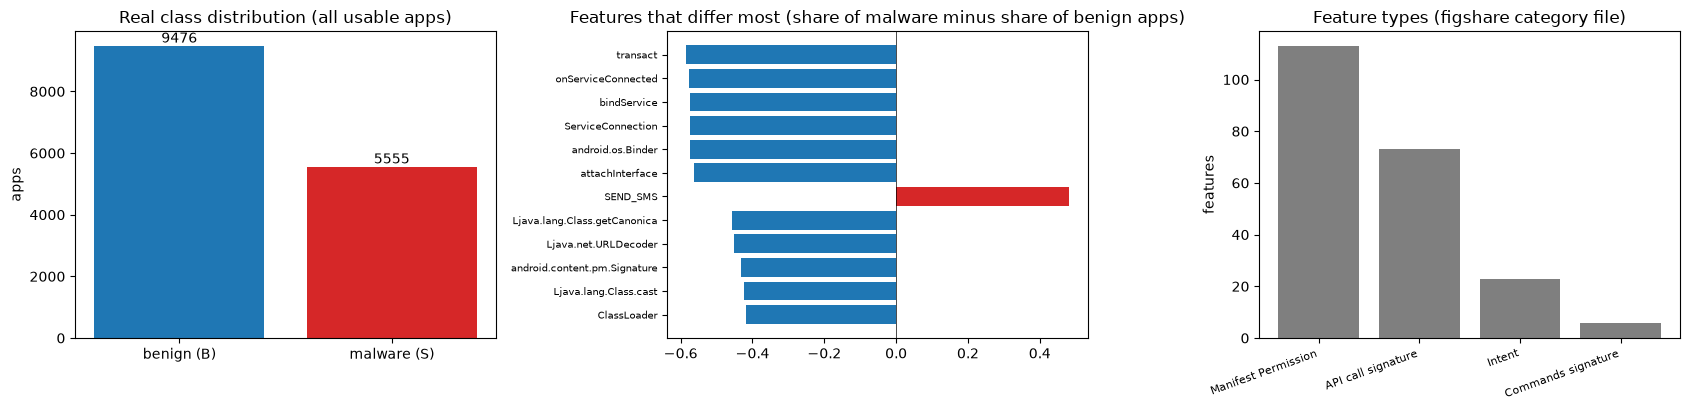

In [5]:
print("Dataset shape (rows, feature columns + label):", raw.shape, "| after cleaning:", data.shape)
print("Number of usable features:", len(feat_cols), "(each is 0/1: absent/present)")
print("First 12 feature names:", feat_cols[:12])
print("Last 5 feature names:  ", feat_cols[-5:])
orig = raw["class"].astype(str).str.strip().value_counts()
print("\nOriginal label values in the CSV `class` column (S = malware, B = benign):")
print(orig.to_string())
print("\nApps use on average %.1f of the %d features (min %d, max %d)" %
      (data[feat_cols].sum(axis=1).mean(), len(feat_cols), data[feat_cols].sum(axis=1).min(), data[feat_cols].sum(axis=1).max()))
display(data.iloc[:5, :8].assign(y=data.y.iloc[:5]))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
ax[0].bar([LABELS[0], LABELS[1]], [int((data.y == 0).sum()), int((data.y == 1).sum())], color=["tab:blue", "tab:red"])
ax[0].set_title("Real class distribution (all usable apps)"); ax[0].set_ylabel("apps")
for i, v in enumerate([int((data.y == 0).sum()), int((data.y == 1).sum())]): ax[0].text(i, v, str(v), ha="center", va="bottom")
prev = pd.DataFrame({"benign": data.loc[data.y == 0, feat_cols].mean(), "malware": data.loc[data.y == 1, feat_cols].mean()})
prev["diff"] = prev.malware - prev.benign
top = prev.reindex(prev["diff"].abs().sort_values(ascending=False).index).head(12)[::-1]
ax[1].barh(range(len(top)), top["diff"], color=np.where(top["diff"] > 0, "tab:red", "tab:blue"))
ax[1].set_yticks(range(len(top))); ax[1].set_yticklabels([s[:28] for s in top.index], fontsize=7)
ax[1].set_title("Features that differ most (share of malware minus share of benign apps)"); ax[1].axvline(0, color="k", lw=0.5)
if len(categories):
    cat = categories.reindex(feat_cols).fillna("unknown").value_counts()
    ax[2].bar(cat.index, cat.values, color="tab:gray"); ax[2].set_title("Feature types (figshare category file)"); ax[2].set_ylabel("features")
    plt.setp(ax[2].get_xticklabels(), rotation=20, ha="right", fontsize=8)
else:
    ax[2].axis("off")
plt.tight_layout(); plt.show()

### Balanced sampling, split and preprocessing

Following the repository convention: a class-balanced random sample, a stratified train/test split, and then `SelectKBest(f_classif)` -> `StandardScaler` -> `PCA(n_components = number of qubits)` -> `MinMaxScaler((0, pi))`. Every transform is **fitted on the training split only**; test angles are clipped to [0, pi]. One PCA component feeds one qubit. The function returns the raw PCA coordinates (for the first scatter plot), the angles (for the quantum model and the classical baselines on identical inputs) and the standardised selected features of all apps (kept only for the "all features" baselines).

sample 3000 apps -> train 2100 (malware 1050) | test 900 (malware 450)
PCA explained variance ratio of the 8 components: [0.203 0.064 0.056 0.039 0.033 0.026 0.025 0.023] sum 0.469


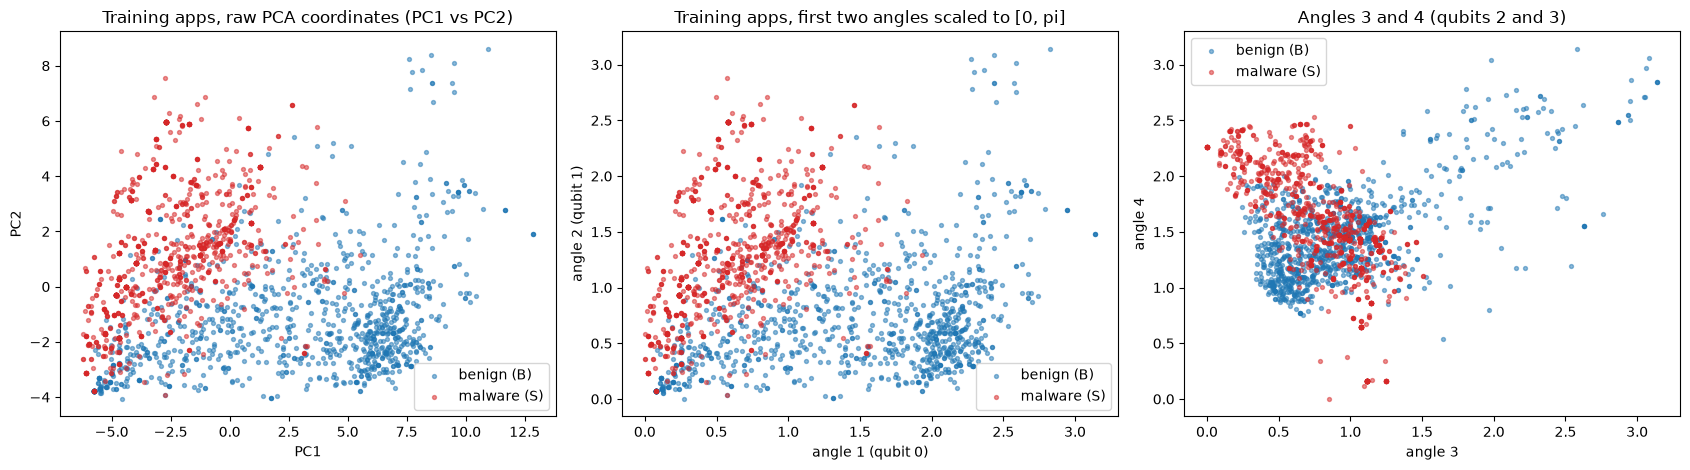

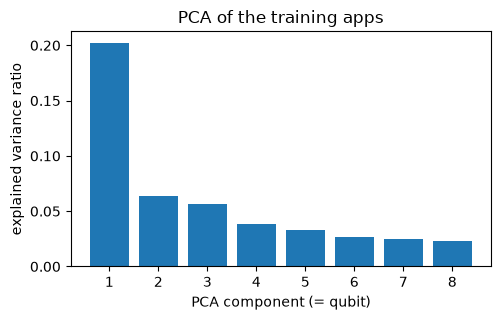

In [6]:
def draw_balanced(seed, n_samples=N_SAMPLES):
    """Balanced random sample of the clean data (half malware, half benign). CHOICE: the paper does not say how many apps it used."""
    per_class = n_samples // 2
    idx = np.concatenate([data.index[data.y == c].to_series().sample(per_class, random_state=seed).values for c in (0, 1)])
    return np.sort(idx)

def prepare(seed, n_qubits, n_samples=N_SAMPLES):
    idx = draw_balanced(seed, n_samples)
    X_all = data.loc[idx, feat_cols].to_numpy(); y_all = data.loc[idx, "y"].to_numpy()
    tr, te = train_test_split(np.arange(len(idx)), test_size=TEST_SIZE, stratify=y_all, random_state=seed)
    Xtr, Xte, ytr, yte = X_all[tr], X_all[te], y_all[tr], y_all[te]
    sel = SelectKBest(f_classif, k=min(K_FEATURES, Xtr.shape[1])).fit(Xtr, ytr)
    sc = StandardScaler().fit(sel.transform(Xtr))
    pca = PCA(n_components=n_qubits, random_state=seed).fit(sc.transform(sel.transform(Xtr)))
    Ztr = pca.transform(sc.transform(sel.transform(Xtr))); Zte = pca.transform(sc.transform(sel.transform(Xte)))
    to_angle = MinMaxScaler((0, np.pi)).fit(Ztr)                      # CHOICE: angles in [0, pi]
    return dict(idx=idx, tr=tr, te=te, Xtr=Xtr, Xte=Xte, ytr=ytr, yte=yte, Ztr=Ztr, Zte=Zte,
                Atr=to_angle.transform(Ztr), Ate=np.clip(to_angle.transform(Zte), 0, np.pi), pca=pca, sel=sel)

D = prepare(SEED, N_QUBITS)
print(f"sample {len(D['idx'])} apps -> train {len(D['ytr'])} (malware {int(D['ytr'].sum())}) | test {len(D['yte'])} (malware {int(D['yte'].sum())})")
print("PCA explained variance ratio of the", N_QUBITS, "components:", np.round(D["pca"].explained_variance_ratio_, 3),
      "sum", round(float(D["pca"].explained_variance_ratio_.sum()), 3))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
for lab, col in [(0, "tab:blue"), (1, "tab:red")]:
    m = D["ytr"] == lab
    ax[0].scatter(D["Ztr"][m, 0], D["Ztr"][m, 1], s=8, alpha=0.5, c=col, label=LABELS[lab])
    ax[1].scatter(D["Atr"][m, 0], D["Atr"][m, 1], s=8, alpha=0.5, c=col, label=LABELS[lab])
    ax[2].scatter(D["Atr"][m, 2], D["Atr"][m, 3], s=8, alpha=0.5, c=col, label=LABELS[lab])
ax[0].set_title("Training apps, raw PCA coordinates (PC1 vs PC2)"); ax[0].set_xlabel("PC1"); ax[0].set_ylabel("PC2")
ax[1].set_title("Training apps, first two angles scaled to [0, pi]"); ax[1].set_xlabel("angle 1 (qubit 0)"); ax[1].set_ylabel("angle 2 (qubit 1)")
ax[2].set_title("Angles 3 and 4 (qubits 2 and 3)"); ax[2].set_xlabel("angle 3"); ax[2].set_ylabel("angle 4")
for a in ax: a.legend()
plt.tight_layout(); plt.show()
fig, ax = plt.subplots(1, 1, figsize=(5.2, 3.3))
ax.bar(range(1, N_QUBITS + 1), D["pca"].explained_variance_ratio_); ax.set_xlabel("PCA component (= qubit)"); ax.set_ylabel("explained variance ratio")
ax.set_title("PCA of the training apps"); plt.tight_layout(); plt.show()

## 3. Classical baselines on identical inputs

Before any quantum circuit, see what ordinary models do with the same 8 angles (SVC with a linear and an RBF kernel, random forest) and, for context, with all 215 original binary features (RBF SVC, random forest). Same split, same training rows, `C = 1`. The positive class is malware. Accuracy, precision, recall and F1 are the metrics named in the paper.

In [7]:
def metrics(y_true, y_pred):
    return {"accuracy": accuracy_score(y_true, y_pred), "precision": precision_score(y_true, y_pred, zero_division=0),
            "recall": recall_score(y_true, y_pred, zero_division=0), "f1": f1_score(y_true, y_pred, zero_division=0)}

def classical_models(P, seed, include_all=True):
    """Classical baselines. Returns {name: (predictions, seconds)}."""
    out = {}
    for name, mk, tr, te in [
        ("SVC linear (angles)", lambda: SVC(kernel="linear", C=C_SVM), "Atr", "Ate"),
        ("SVC RBF (angles)", lambda: SVC(kernel="rbf", C=C_SVM), "Atr", "Ate"),
        ("Random forest (angles)", lambda: RandomForestClassifier(n_estimators=200, random_state=seed, n_jobs=1), "Atr", "Ate"),
        ("SVC RBF (all 215 features)", lambda: SVC(kernel="rbf", C=C_SVM), "Xtr", "Xte"),
        ("Random forest (all 215 features)", lambda: RandomForestClassifier(n_estimators=200, random_state=seed, n_jobs=1), "Xtr", "Xte")]:
        if "all 215" in name and not include_all: continue
        t0 = time.perf_counter(); m = mk().fit(P[tr], P["ytr"]); pred = m.predict(P[te]); out[name] = (pred, time.perf_counter() - t0)
    return out

base = classical_models(D, SEED)
print(pd.DataFrame({k: {**metrics(D["yte"], p), "time (s)": t} for k, (p, t) in base.items()}).T.round(4).to_string())

                                  accuracy  precision  recall      f1  time (s)
SVC linear (angles)                 0.9244     0.9361  0.9111  0.9234    0.3566
SVC RBF (angles)                    0.9489     0.9676  0.9289  0.9478    0.5124
Random forest (angles)              0.9567     0.9660  0.9467  0.9562    6.3461
SVC RBF (all 215 features)          0.9711     0.9862  0.9556  0.9707    3.9306
Random forest (all 215 features)    0.9656     0.9816  0.9489  0.9650   11.9489


## 4. Quantum Circuit Architecture

The paper gives no circuit, so this notebook uses the standard ZZ feature map of Havlicek et al. (Qiskit `zz_feature_map`): `reps` times, a Hadamard on every qubit, a phase `P(2 x_i)` on every qubit, and for every neighbouring pair `(i, i+1)` the entangling block `CX - P(2 (pi - x_i)(pi - x_{i+1})) - CX`. The kernel circuit that a quantum computer would run for one kernel entry is `U(a)` followed by `U(b)^dagger` and a measurement of all qubits; the kernel value is the probability of the all-zero outcome. The cells below draw the feature map exactly as executed here (8 qubits, `reps = 2`, linear entanglement), draw the complete fidelity circuit for one pair of real apps, print qubit count, depth and parameter counts, and assert that the all-zero probability of the fidelity circuit equals the state-vector overlap used by `FidelityStatevectorKernel`.

The kernel has **no trainable circuit parameters**: the 8 parameters of the feature map are the data angles. All learning is done by the classical SVM optimiser on the kernel matrix. Every circuit detail is a `# CHOICE:` because the paper omits it.

 qubits  depth (library gate)  depth (basis gates)               gates  data parameters  trainable parameters
      4                    19                   19 {'u': 22, 'cx': 12}                4                     0
      6                    25                   25 {'u': 34, 'cx': 20}                6                     0
      8                    31                   31 {'u': 46, 'cx': 28}                8                     0
     10                    37                   37 {'u': 58, 'cx': 36}               10                     0


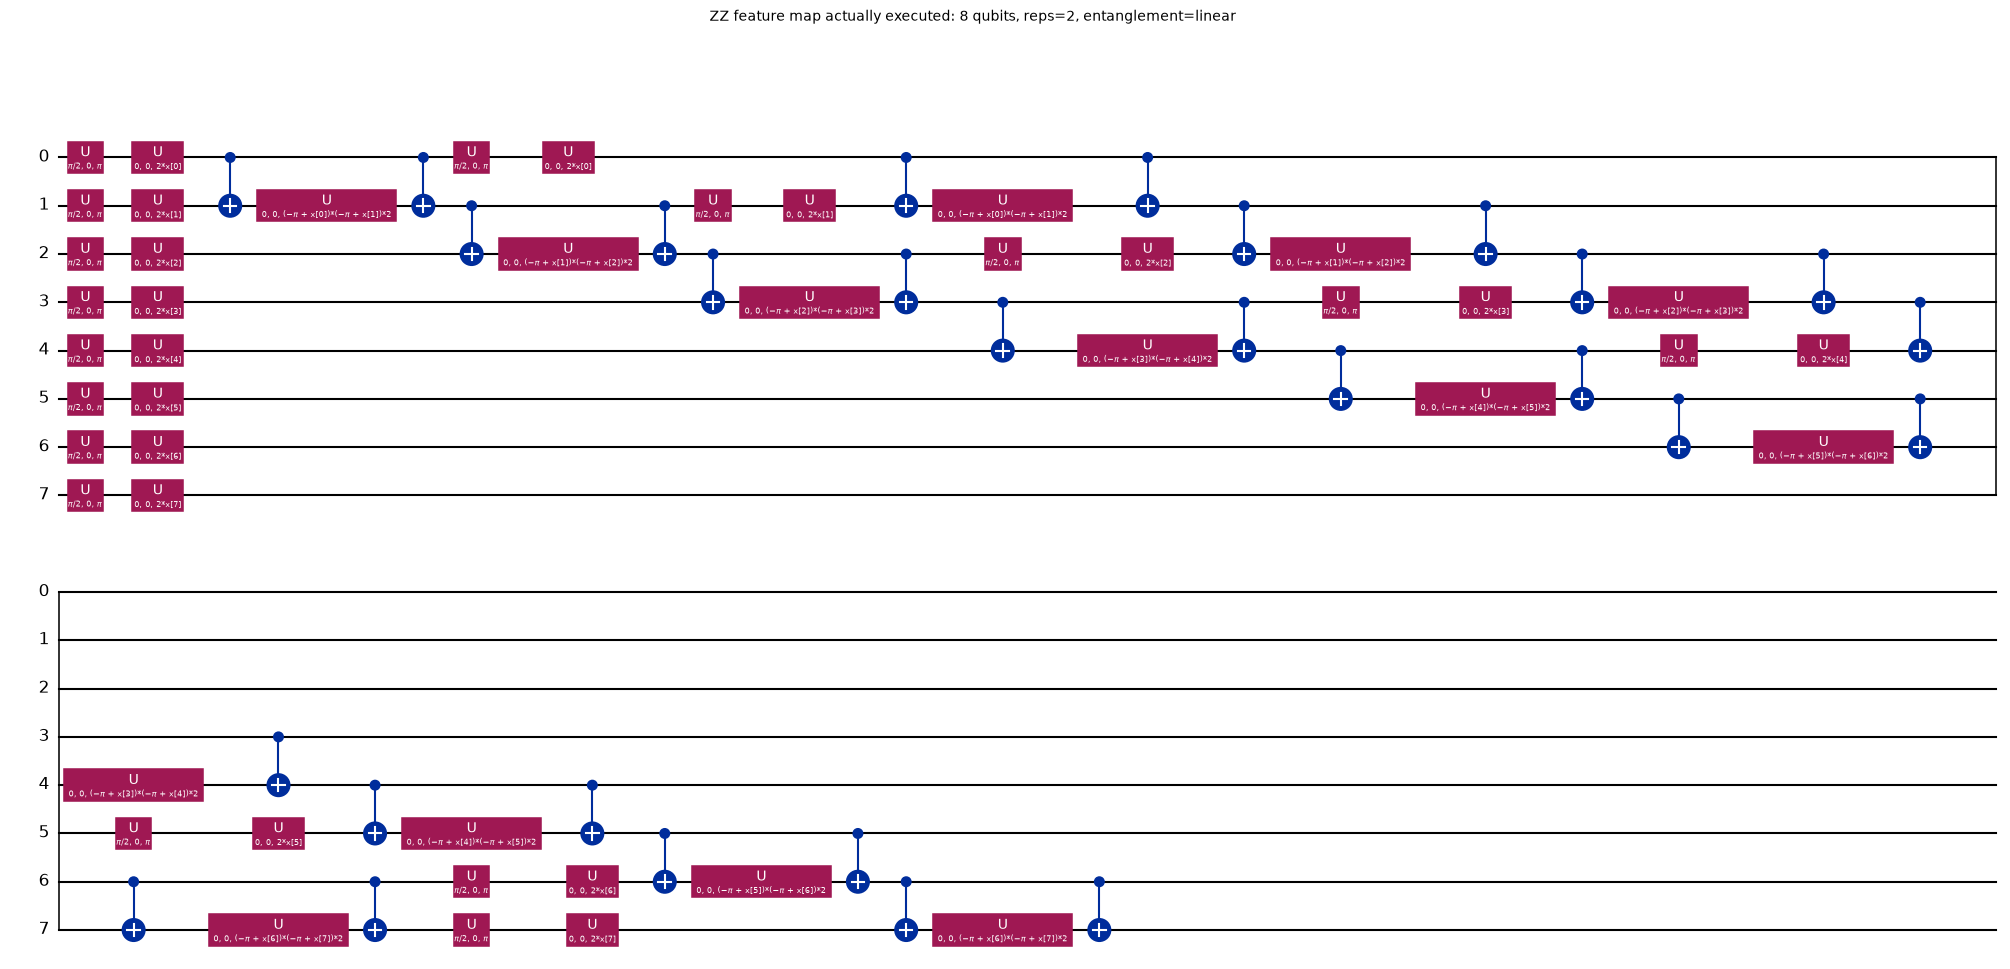

In [8]:
FMAPS = {}
def get_fm(n):
    if n not in FMAPS:
        FMAPS[n] = zz_feature_map(feature_dimension=n, reps=FM_REPS, entanglement=ENTANGLEMENT)   # CHOICE: ZZ map, reps=2, linear
    return FMAPS[n]

fm = get_fm(N_QUBITS)
rows = []
for n in sorted(set(QUBIT_SWEEP)):
    c = get_fm(n); dec = c.decompose(reps=3)
    rows.append({"qubits": n, "depth (library gate)": c.decompose().depth(), "depth (basis gates)": dec.depth(),
                 "gates": dict(dec.count_ops()), "data parameters": c.num_parameters, "trainable parameters": 0})
print(pd.DataFrame(rows).to_string(index=False))
fig = fm.decompose().draw("mpl", fold=40, scale=0.75)
fig.suptitle(f"ZZ feature map actually executed: {N_QUBITS} qubits, reps={FM_REPS}, entanglement={ENTANGLEMENT}", fontsize=10)
display(fig)
plt.close(fig)

fidelity circuit: qubits 8 | depth 63 | trainable parameters 0 (the 16 angles are the data of the two apps)


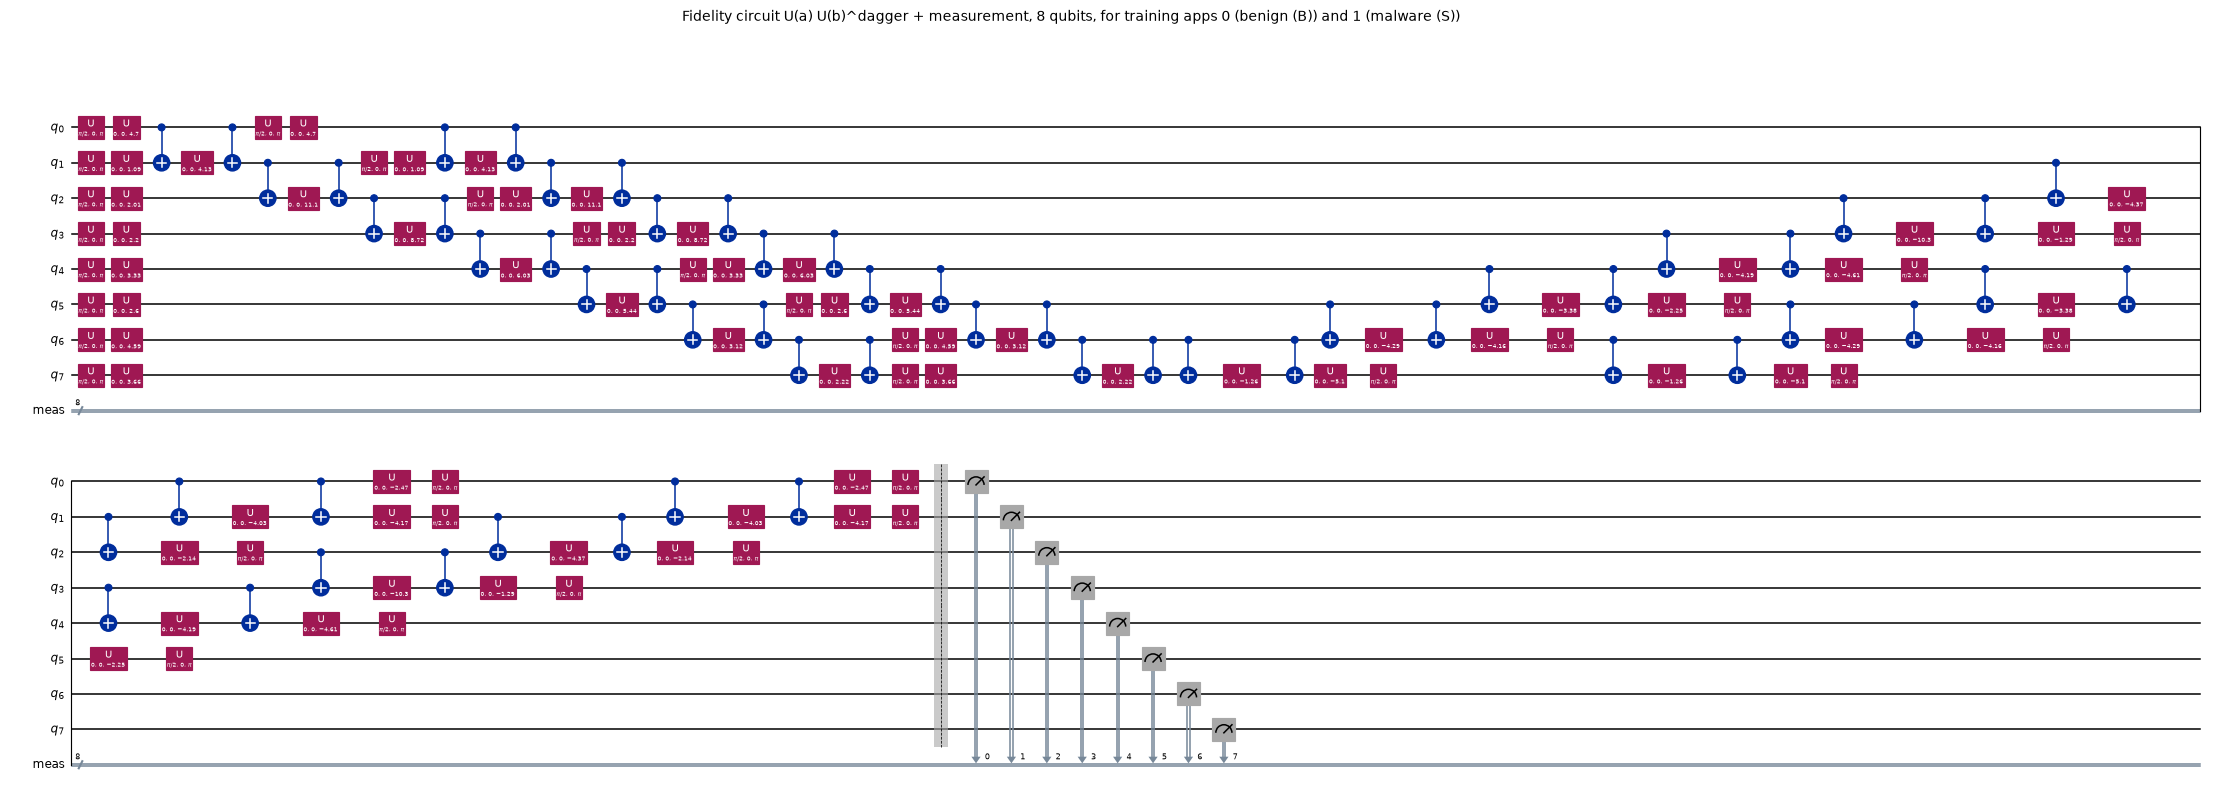

P(all zeros) of the executed circuit = 0.000142 | |<phi(a)|phi(b)>|^2 = 0.000142
assertion passed: the kernel entry equals the all-zero probability of the circuit above


In [9]:
# The circuit run for one kernel entry on a real pair of apps: U(a) then U(b)^dagger, then measurement (what a QPU would execute)
a_demo, b_demo = D["Atr"][0], D["Atr"][1]
fid = QuantumCircuit(N_QUBITS)
fid.compose(fm.assign_parameters(a_demo), inplace=True)
fid.compose(fm.assign_parameters(b_demo).inverse(), inplace=True)
fid.measure_all()
print(f"fidelity circuit: qubits {fid.num_qubits} | depth {fid.decompose().depth()} | trainable parameters 0 (the {2 * N_QUBITS} angles are the data of the two apps)")
fig = fid.decompose().draw("mpl", fold=60, scale=0.55)
fig.suptitle(f"Fidelity circuit U(a) U(b)^dagger + measurement, {N_QUBITS} qubits, for training apps 0 ({LABELS[int(D['ytr'][0])]}) and 1 ({LABELS[int(D['ytr'][1])]})", fontsize=10)
display(fig); plt.close(fig)
p_zero = Statevector(fid.remove_final_measurements(inplace=False)).probabilities()[0]
sa, sb = Statevector(fm.assign_parameters(a_demo)).data, Statevector(fm.assign_parameters(b_demo)).data
overlap = abs(np.vdot(sa, sb)) ** 2
print(f"P(all zeros) of the executed circuit = {p_zero:.6f} | |<phi(a)|phi(b)>|^2 = {overlap:.6f}")
assert np.isclose(p_zero, overlap), "the fidelity circuit and the state overlap disagree"
print("assertion passed: the kernel entry equals the all-zero probability of the circuit above")

### The same feature map in PennyLane

The paper's lab uses PennyLane. Below the identical gate sequence is written as a PennyLane QNode (Hadamard, phase shift, CNOT - phase - CNOT), drawn with `qml.draw_mpl`, and its kernel on 12 real training apps is asserted equal to the Qiskit kernel. This shows that nothing in the results depends on the choice of framework.

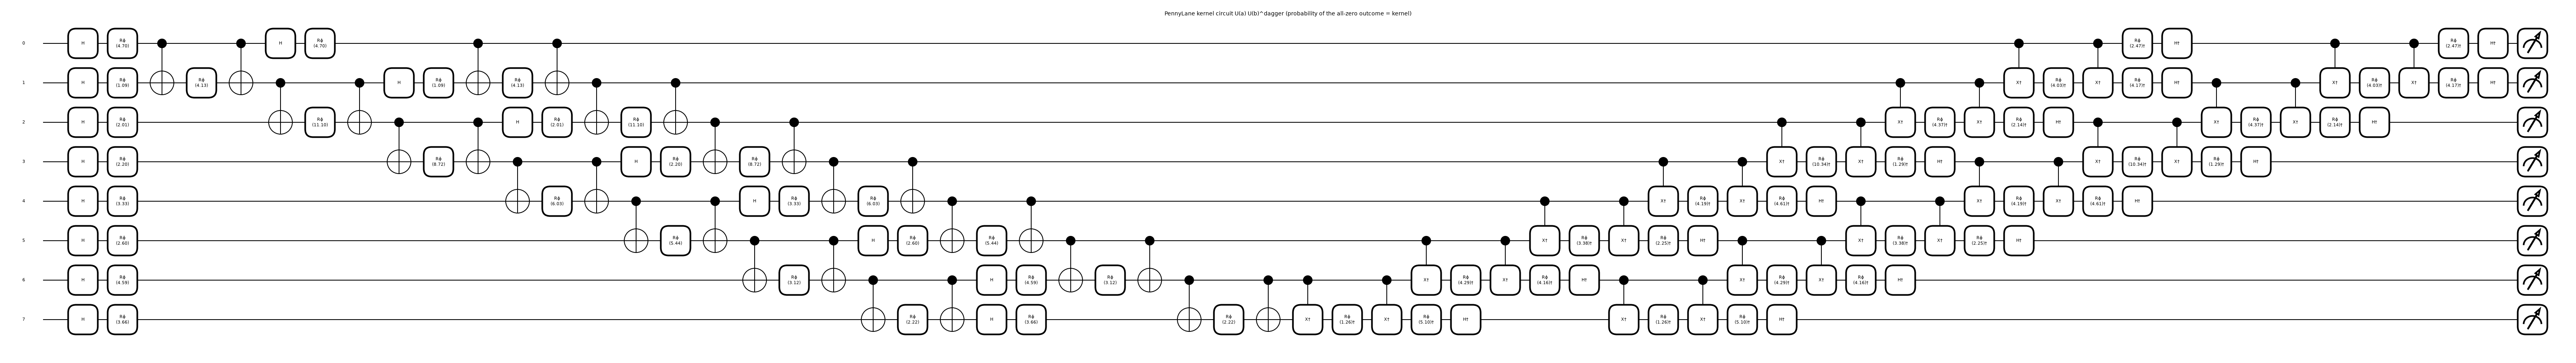

max |K_pennylane - K_qiskit| on 12 apps: 7.105427357601002e-15
assertion passed: PennyLane and Qiskit give the same quantum kernel


In [10]:
dev = qml.device("default.qubit", wires=N_QUBITS)

def zz_layers(x):
    """PennyLane version of Qiskit's zz_feature_map(reps=FM_REPS, entanglement='linear')."""
    for _ in range(FM_REPS):
        for q in range(N_QUBITS): qml.Hadamard(wires=q)
        for q in range(N_QUBITS): qml.PhaseShift(2 * x[q], wires=q)
        for i in range(N_QUBITS - 1):
            qml.CNOT(wires=[i, i + 1])
            qml.PhaseShift(2 * (np.pi - x[i]) * (np.pi - x[i + 1]), wires=i + 1)
            qml.CNOT(wires=[i, i + 1])

@qml.qnode(dev)
def kernel_circuit(a, b):
    zz_layers(a)
    qml.adjoint(zz_layers)(b)
    return qml.probs(wires=range(N_QUBITS))

fig, ax = qml.draw_mpl(kernel_circuit, decimals=2, fontsize=8)(a_demo, b_demo)
fig.suptitle("PennyLane kernel circuit U(a) U(b)^dagger (probability of the all-zero outcome = kernel)", fontsize=10)
display(fig); plt.close(fig)

pts = D["Atr"][:12]
K_pl = np.array([[float(kernel_circuit(a, b)[0]) for b in pts] for a in pts])
K_qk = FidelityStatevectorKernel(feature_map=fm).evaluate(pts)
print("max |K_pennylane - K_qiskit| on 12 apps:", float(np.abs(K_pl - K_qk).max()))
assert np.allclose(K_pl, K_qk, atol=1e-8)
print("assertion passed: PennyLane and Qiskit give the same quantum kernel")

## 5. The quantum kernel, computed by hand and by Qiskit

The kernel is `K(a, b) = |<phi(a)|phi(b)>|^2`. The cell below turns every app into its state vector (a vectorised NumPy simulation of exactly the gates drawn above, asserted equal to Qiskit's `Statevector` of the real circuit for every qubit count used), builds the kernel by hand as a matrix product and compares it with `FidelityStatevectorKernel` of Qiskit Machine Learning on a few apps. The `bandwidth` multiplies the angles before they enter the circuit: small angles keep the states closer, so the kernel does not become near-diagonal (a known trap of quantum kernels). It is chosen on a validation split cut from the **training data only**.

In [11]:
_BASIS = {}
def _basis(n):
    if n not in _BASIS:
        idx = np.arange(2 ** n)
        bits = ((idx[:, None] >> np.arange(n)[None, :]) & 1).astype(float)          # qubit i = bit i of the basis index (Qiskit order)
        pairs = np.stack([(bits[:, i] != bits[:, i + 1]).astype(float) for i in range(n - 1)], axis=1)   # parity of neighbouring qubits
        ab = idx[:, None] & idx[None, :]
        par = np.zeros(ab.shape, dtype=np.int64)
        for k in range(n): par ^= (ab >> k) & 1
        H = (1 - 2 * par) / np.sqrt(2.0 ** n)                                        # Hadamard on all n qubits
        _BASIS[n] = (bits, pairs, H)
    return _BASIS[n]

def quantum_states_vectorised(X, n_qubits, bandwidth=1.0):
    """|phi(x)> of the ZZ feature map (linear entanglement) for every row of X, simulated exactly with NumPy.
    Same gate list as the Qiskit circuit: [H on all qubits, P(2 x_i), CX P(2 (pi-x_i)(pi-x_j)) CX on neighbours] repeated FM_REPS times."""
    assert ENTANGLEMENT == "linear"
    X = np.asarray(X, dtype=float) * bandwidth
    bits, pairs, H = _basis(n_qubits)
    theta = 2 * X @ bits.T + (2 * (np.pi - X[:, :-1]) * (np.pi - X[:, 1:])) @ pairs.T
    phase = np.exp(1j * theta)
    psi = np.zeros((len(X), 2 ** n_qubits), dtype=complex); psi[:, 0] = 1.0
    for _ in range(FM_REPS):
        psi = (psi @ H) * phase
    return psi

def quantum_states_qiskit(X, n_qubits, bandwidth=1.0):
    f = get_fm(n_qubits)
    return np.array([Statevector(f.assign_parameters(x * bandwidth)).data for x in X])

quantum_states = quantum_states_vectorised       # used by every experiment below

# The vectorised simulator must reproduce the states of the real Qiskit circuits (up to a global phase) for every qubit count used
rng_chk = np.random.default_rng(SEED)
for n in sorted(set(QUBIT_SWEEP)):
    Xc = rng_chk.uniform(0, np.pi, size=(6, n))
    a, b = quantum_states_vectorised(Xc, n, 0.7), quantum_states_qiskit(Xc, n, 0.7)
    ov = np.abs(np.einsum("ij,ij->i", a.conj(), b))
    assert np.allclose(ov, 1.0, atol=1e-9) and np.allclose(np.linalg.norm(a, axis=1), 1.0), f"simulator mismatch at {n} qubits"
print("vectorised simulator equals the Qiskit circuit states (up to a global phase) for qubit counts", sorted(set(QUBIT_SWEEP)))

def kernel_from_states(SA, SB):
    return np.abs(SA.conj() @ SB.T) ** 2

# by-hand kernel vs Qiskit's FidelityStatevectorKernel on 20 training apps
sub = D["Atr"][:20]
K_hand = kernel_from_states(quantum_states(sub, N_QUBITS), quantum_states(sub, N_QUBITS))
K_fsk = FidelityStatevectorKernel(feature_map=fm).evaluate(sub)
print("kernel by hand equals FidelityStatevectorKernel:", bool(np.allclose(K_hand, K_fsk)), "| max abs difference", float(np.abs(K_hand - K_fsk).max()))
assert np.allclose(K_hand, K_fsk)

def choose_bandwidth(A, y, seed, n_qubits):
    """Bandwidth chosen on a validation split cut from the training data only (never sees the test set)."""
    rng = np.random.default_rng(seed)
    pick = rng.choice(len(A), size=min(VAL_POOL, len(A)), replace=False)
    Af, Av, yf, yv = train_test_split(A[pick], y[pick], test_size=0.3, stratify=y[pick], random_state=seed)
    scores = {}
    for bw in BANDWIDTH_CHOICES:
        Sf, Sv = quantum_states(Af, n_qubits, bw), quantum_states(Av, n_qubits, bw)
        svm = SVC(kernel="precomputed", C=C_SVM).fit(kernel_from_states(Sf, Sf), yf)
        scores[bw] = svm.score(kernel_from_states(Sv, Sf), yv)
    best = max(BANDWIDTH_CHOICES, key=lambda b: (scores[b], b))     # ties -> larger bandwidth
    return best, scores

bw_main, bw_scores = choose_bandwidth(D["Atr"], D["ytr"], SEED, N_QUBITS)
print("validation accuracy per bandwidth:", {k: round(v, 4) for k, v in bw_scores.items()}, "-> chosen", bw_main)

vectorised simulator equals the Qiskit circuit states (up to a global phase) for qubit counts [4, 6, 8, 10]


kernel by hand equals FidelityStatevectorKernel: True | max abs difference 1.3322676295501878e-15


validation accuracy per bandwidth:

 {1.0: 0.9, 0.5: 0.9222, 0.25: 0.9222, 0.1: 0.9222} -> chosen 0.5


## 6. Train the QSVM

`QSVC` is a scikit-learn SVM whose kernel is the quantum kernel. We train it on the training apps with the chosen bandwidth, then repeat the same model by hand (state vectors -> kernel matrices -> `SVC(kernel="precomputed")`). Their predictions must be identical. The kernel matrix of the training apps is also shown with the apps sorted by class: two bright blocks mean that apps of the same class look alike to the circuit.

QSVC (Qiskit): 736.3 s | by hand: 2.0 s | predictions identical: True
QSVM metrics on the test split: {'accuracy': 0.9333, 'precision': 0.9514, 'recall': 0.9133, 'f1': 0.932}


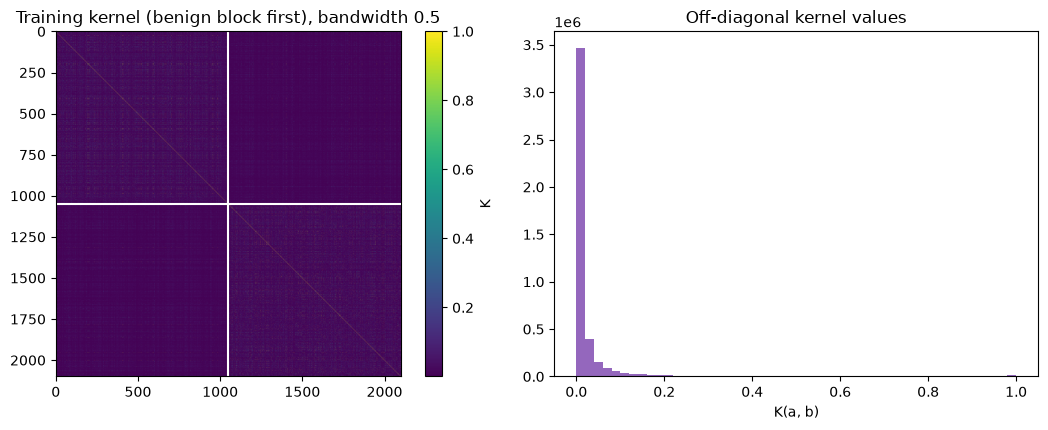

off-diagonal kernel: mean 0.027, std 0.090


In [12]:
t0 = time.perf_counter()
qsvc = QSVC(quantum_kernel=FidelityStatevectorKernel(feature_map=fm), C=C_SVM)
qsvc.fit(D["Atr"] * bw_main, D["ytr"])
pred_qsvc = qsvc.predict(D["Ate"] * bw_main)
t_qsvc = time.perf_counter() - t0

t0 = time.perf_counter()
S_tr, S_te = quantum_states(D["Atr"], N_QUBITS, bw_main), quantum_states(D["Ate"], N_QUBITS, bw_main)
K_tr, K_te = kernel_from_states(S_tr, S_tr), kernel_from_states(S_te, S_tr)
pred_hand = SVC(kernel="precomputed", C=C_SVM).fit(K_tr, D["ytr"]).predict(K_te)
t_hand = time.perf_counter() - t0

print(f"QSVC (Qiskit): {t_qsvc:.1f} s | by hand: {t_hand:.1f} s | predictions identical:", bool(np.array_equal(pred_qsvc, pred_hand)))
assert np.array_equal(pred_qsvc, pred_hand)
print("QSVM metrics on the test split:", {k: round(v, 4) for k, v in metrics(D["yte"], pred_qsvc).items()})

order = np.argsort(D["ytr"], kind="stable")
fig, ax = plt.subplots(1, 2, figsize=(11, 4.4))
im = ax[0].imshow(K_tr[np.ix_(order, order)], cmap="viridis"); plt.colorbar(im, ax=ax[0], label="K")
nb = int((D["ytr"] == 0).sum()); ax[0].axhline(nb - 0.5, color="white"); ax[0].axvline(nb - 0.5, color="white")
ax[0].set_title(f"Training kernel (benign block first), bandwidth {bw_main}")
off = K_tr[~np.eye(len(K_tr), dtype=bool)]
ax[1].hist(off, bins=50, color="tab:purple"); ax[1].set_title("Off-diagonal kernel values"); ax[1].set_xlabel("K(a, b)")
plt.tight_layout(); plt.show()
print(f"off-diagonal kernel: mean {off.mean():.3f}, std {off.std():.3f}")

### Confusion matrices

Every test app lands in one of four boxes. Malware is the positive class: true positive = malware flagged, false negative = malware missed, false positive = false alarm on a benign app, true negative = benign app passed.

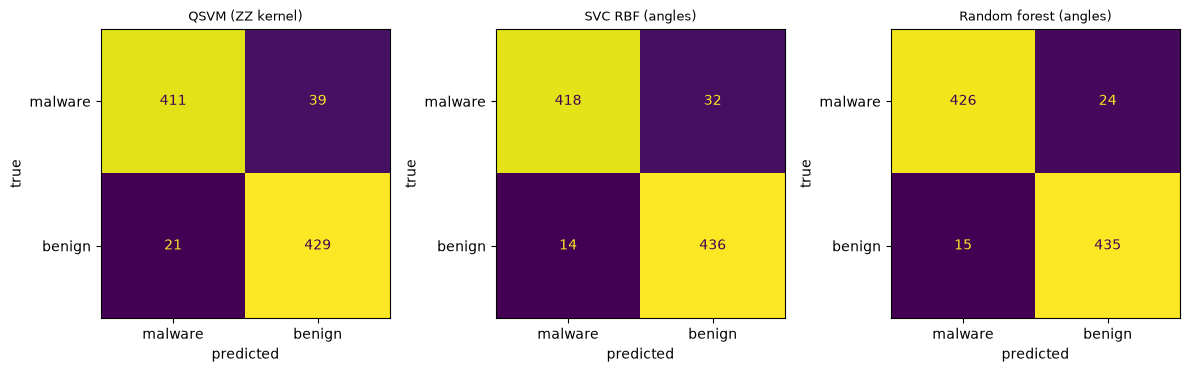

In [13]:
preds = {"QSVM (ZZ kernel)": pred_qsvc}
for k, (p, t) in base.items():
    if "angles" in k and "linear" not in k: preds[k] = p
fig, axes = plt.subplots(1, len(preds), figsize=(4.0 * len(preds), 3.8))
for ax, (name, p) in zip(axes, preds.items()):
    cm = confusion_matrix(D["yte"], p, labels=[1, 0])
    ConfusionMatrixDisplay(cm, display_labels=["malware", "benign"]).plot(ax=ax, colorbar=False)
    ax.set_title(name, fontsize=9); ax.set_xlabel("predicted"); ax.set_ylabel("true")
plt.tight_layout(); plt.show()

## 7. Repeated runs and the qubit-count sensitivity study

One split can be lucky. For every qubit count in `QUBIT_SWEEP` and every seed we draw a fresh balanced sample, split, fit the whole preprocessing on the training part, choose the bandwidth on a validation slice of the training part, train the QSVM and the baselines, and record accuracy, precision, recall, F1 and the time of training plus prediction. We also record how many test apps have an **exact copy** (all 215 features) in the training split, and the accuracy on the test apps that have no copy; section 9 explains why. The 215-feature baselines do not depend on the qubit count and are computed once per seed.

In [14]:
def seen_mask(P):
    """True for test apps whose full 215-bit pattern also occurs in the training split of the same sample."""
    train_keys = {row.tobytes() for row in P["Xtr"].astype(np.uint8)}
    return np.array([row.tobytes() in train_keys for row in P["Xte"].astype(np.uint8)])

records = []
t_start = time.time()
for seed in [SEED + s for s in range(N_SEEDS)]:
    for nq in QUBIT_SWEEP:
        P = prepare(seed, nq)
        seen = seen_mask(P)
        bw, _ = choose_bandwidth(P["Atr"], P["ytr"], seed, nq)
        t0 = time.perf_counter()
        Str, Ste = quantum_states(P["Atr"], nq, bw), quantum_states(P["Ate"], nq, bw)
        pred_q = SVC(kernel="precomputed", C=C_SVM).fit(kernel_from_states(Str, Str), P["ytr"]).predict(kernel_from_states(Ste, Str))
        t_q = time.perf_counter() - t0
        row = dict(seed=seed, qubits=nq, model="QSVM (ZZ kernel)", bandwidth=bw, seconds=t_q, frac_test_seen=seen.mean(),
                   acc_unseen=accuracy_score(P["yte"][~seen], pred_q[~seen]) if (~seen).sum() > 0 else np.nan, **metrics(P["yte"], pred_q))
        records.append(row)
        for name, (p, t) in classical_models(P, seed, include_all=(nq == N_QUBITS)).items():
            q = np.nan if "all 215" in name else nq
            records.append(dict(seed=seed, qubits=q, model=name, bandwidth=np.nan, seconds=t, frac_test_seen=seen.mean(),
                                acc_unseen=accuracy_score(P["yte"][~seen], p[~seen]) if (~seen).sum() > 0 else np.nan, **metrics(P["yte"], p)))
    print(f"seed {seed} done, {time.time() - t_start:.0f} s elapsed", flush=True)
res = pd.DataFrame(records)
print("total time %.1f min" % ((time.time() - t_start) / 60))

seed 42 done, 73 s elapsed


seed 43 done, 135 s elapsed


seed 44 done, 191 s elapsed


seed 45 done, 256 s elapsed


seed 46 done, 316 s elapsed


total time 5.3 min


accuracy         precision          recall  \
                                     mean     std      mean     std    mean   
model                                                                         
QSVM (ZZ kernel)                   0.9327  0.0093    0.9463  0.0192  0.9178   
Random forest (all 215 features)   0.9687  0.0035    0.9766  0.0079  0.9604   
Random forest (angles)             0.9564  0.0032    0.9635  0.0085  0.9489   
SVC RBF (all 215 features)         0.9709  0.0047    0.9840  0.0031  0.9573   
SVC RBF (angles)                   0.9444  0.0038    0.9559  0.0090  0.9320   
SVC linear (angles)                0.9291  0.0043    0.9361  0.0090  0.9213   

                                              f1         acc_unseen          \
                                     std    mean     std       mean     std   
model                                                                         
QSVM (ZZ kernel)                  0.0093  0.9317  0.0089     0.9085  0.0195   
Random forest (all 215 features)  0.0082  0.9684  0.0035     0.9488  0.0047   
Random forest (angles)            0.0052  0.9561  0.0030     0.9297  0.0051   
SVC RBF (all 215 features)        0.0110  0.9705  0.0050     0.9629  0.0066   
SVC RBF (angles)                  0.0084  0.9437  0.0038     0.9303  0.0082   
SVC linear (angles)               0.0156  0.9285  0.0050     0.9150  0.0076   

                                 seconds          
                                    mean     std  
model                                             
QSVM (ZZ kernel)                  2.8717  0.8071  
Random forest (all 215 features)  7.0240  1.4671  
Random forest (angles)            6.3141  1.2189  
SVC RBF (all 215 features)        3.3178  0.8001  
SVC RBF (angles)                  0.7332  0.2389  
SVC linear (angles)               0.4475  0.2395

Accuracy versus number of qubits (mean over seeds):


QSVM         SVC RBF              RF        
          mean     std    mean     std    mean     std
qubits                                                
4.0     0.9144  0.0032  0.9293  0.0060  0.9507  0.0049
6.0     0.9238  0.0080  0.9387  0.0018  0.9564  0.0047
8.0     0.9327  0.0093  0.9444  0.0038  0.9564  0.0032
10.0    0.9309  0.0043  0.9438  0.0027  0.9582  0.0044

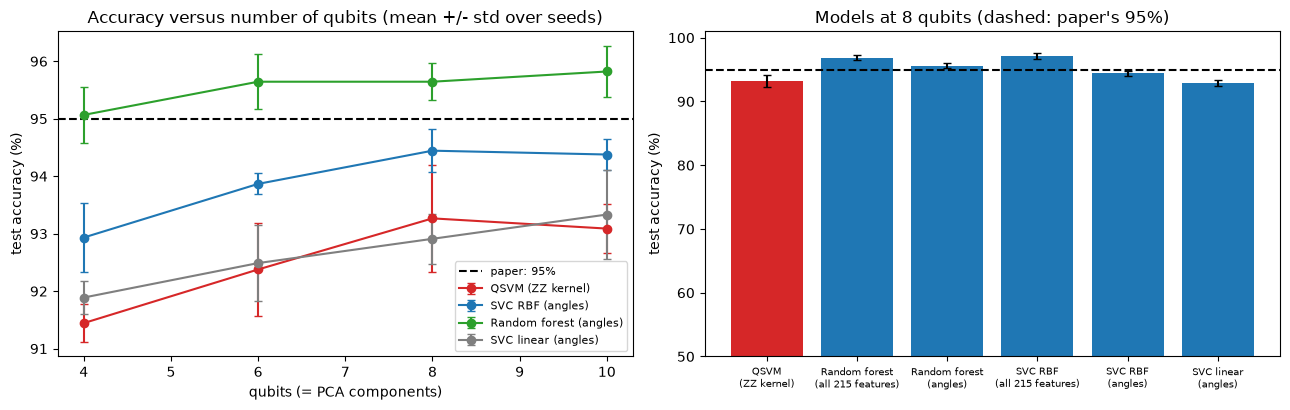

In [15]:
main = res[(res.qubits == N_QUBITS) | res.qubits.isna()]
summary = main.groupby("model")[["accuracy", "precision", "recall", "f1", "acc_unseen", "seconds"]].agg(["mean", "std"]).round(4)
display(summary)

q_sweep = res[res.model == "QSVM (ZZ kernel)"].groupby("qubits")[["accuracy", "f1"]].agg(["mean", "std"]).round(4)
rbf_sweep = res[res.model == "SVC RBF (angles)"].groupby("qubits")[["accuracy"]].agg(["mean", "std"]).round(4)
rf_sweep = res[res.model == "Random forest (angles)"].groupby("qubits")[["accuracy"]].agg(["mean", "std"]).round(4)
print("Accuracy versus number of qubits (mean over seeds):")
display(pd.concat({"QSVM": q_sweep["accuracy"], "SVC RBF": rbf_sweep["accuracy"], "RF": rf_sweep["accuracy"]}, axis=1))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for name, col in [("QSVM (ZZ kernel)", "tab:red"), ("SVC RBF (angles)", "tab:blue"), ("Random forest (angles)", "tab:green"), ("SVC linear (angles)", "tab:gray")]:
    g = res[res.model == name].groupby("qubits")["accuracy"].agg(["mean", "std"])
    ax[0].errorbar(g.index, g["mean"] * 100, yerr=g["std"].fillna(0) * 100, marker="o", capsize=3, color=col, label=name)
ax[0].axhline(PAPER_ACCURACY * 100, color="k", ls="--", label="paper: 95%")
ax[0].set_xlabel("qubits (= PCA components)"); ax[0].set_ylabel("test accuracy (%)"); ax[0].set_title("Accuracy versus number of qubits (mean +/- std over seeds)"); ax[0].legend(fontsize=8)
order_models = list(summary.index)
ax[1].bar(range(len(order_models)), summary[("accuracy", "mean")] * 100, yerr=summary[("accuracy", "std")].fillna(0) * 100, capsize=3,
          color=["tab:red" if m.startswith("QSVM") else "tab:blue" for m in order_models])
ax[1].axhline(PAPER_ACCURACY * 100, color="k", ls="--")
ax[1].set_xticks(range(len(order_models))); ax[1].set_xticklabels([m.replace(" (", "\n(") for m in order_models], fontsize=7)
ax[1].set_ylim(50, 101); ax[1].set_ylabel("test accuracy (%)"); ax[1].set_title(f"Models at {N_QUBITS} qubits (dashed: paper's 95%)")
plt.tight_layout(); plt.show()

## 8. Re-drawing the paper's results

The paper has no results table or figure for the QSVM: its figures are screenshots of the lab pages (Figures 2 and 3) and bar charts of a student questionnaire (Figures 4 to 11). The only quantitative result is the 95% accuracy of the abstract. The nearest thing to redraw is a table of the four metrics the paper names (accuracy, precision, recall, F1) for the QSVM, which is the table printed in section 7 and repeated below as percentages, next to the paper's single number.

In [16]:
q = main[main.model == "QSVM (ZZ kernel)"]
tab = pd.DataFrame({"paper": {"accuracy": "95% (abstract)", "precision": "named, not reported", "recall": "named, not reported", "f1": "named, not reported"},
                    "this notebook (mean +/- std)": {m: f"{q[m].mean() * 100:.2f} +/- {q[m].std() * 100:.2f} %" if len(q) > 1 else f"{q[m].mean() * 100:.2f} %" for m in ["accuracy", "precision", "recall", "f1"]}})
display(tab)

,paper,this notebook (mean +/- std)
accuracy,95% (abstract),93.27 +/- 0.93 %
precision,"named, not reported",94.63 +/- 1.92 %
recall,"named, not reported",91.78 +/- 0.93 %
f1,"named, not reported",93.17 +/- 0.89 %


## 9. Duplicates in Drebin-215 and what they do to the score

Drebin-215 contains many apps with exactly the same 215-bit pattern (the count was printed in section 1). When such copies land on both sides of a random split, the test set contains patterns the model has already seen, which inflates every score. The paper does not mention duplicates. The table shows, for the models at the main qubit count, the share of test apps that have an exact copy in the training split and the accuracy on the test apps that have **no** copy.

In [17]:
dup = main.groupby("model").agg(accuracy=("accuracy", "mean"), accuracy_on_unseen_patterns=("acc_unseen", "mean"), share_of_test_apps_with_copy_in_train=("frac_test_seen", "mean")).round(4)
display(dup)

,accuracy,accuracy_on_unseen_patterns,share_of_test_apps_with_copy_in_train
model,,,
QSVM (ZZ kernel),0.9327,0.9085,0.4058
Random forest (all 215 features),0.9687,0.9488,0.4058
Random forest (angles),0.9564,0.9297,0.4058
SVC RBF (all 215 features),0.9709,0.9629,0.4058
SVC RBF (angles),0.9444,0.9303,0.4058
SVC linear (angles),0.9291,0.9150,0.4058


## 10. Comparison with the paper

The paper offers one checkable number. "Reproduced" means within 2 accuracy points of 95%; otherwise the verdict is "not reached" (below) or "exceeded" (above), with the gap. Claims about the student survey, the lab design and the ten-module programme are not computational and cannot be checked.

In [18]:
qa = main[main.model == "QSVM (ZZ kernel)"]["accuracy"]
qa_mean, qa_std = float(qa.mean()), float(qa.std()) if len(qa) > 1 else 0.0
gap = qa_mean - PAPER_ACCURACY
verdict_acc = "reproduced" if abs(gap) <= TOLERANCE else ("exceeded" if gap > 0 else "not reached")
best_classical = main[main.model != "QSVM (ZZ kernel)"].groupby("model")["accuracy"].mean()
rbf_a = float(best_classical["SVC RBF (angles)"]); rf_a = float(best_classical["Random forest (angles)"]); rf_all = float(best_classical["Random forest (all 215 features)"])
sweep_acc = res[res.model == "QSVM (ZZ kernel)"].groupby("qubits")["accuracy"].mean()

claims = pd.DataFrame([
    ["QSVM accuracy 95% on Drebin-215 (abstract)", "95%", f"{qa_mean * 100:.2f} +/- {qa_std * 100:.2f} % ({N_QUBITS} qubits, {len(qa)} seeds)", f"{verdict_acc} (gap {gap * 100:+.2f} points)"],
    ["Best QSVM accuracy over the qubit sweep (sensitivity, not a claim of the paper)", "-", "; ".join(f"{int(k)}q: {v * 100:.1f}%" for k, v in sweep_acc.items()), "context only"],
    ["QSVM compared with a classical SVM / RF on the same inputs (the paper has no baseline)", "none", f"RBF SVC {rbf_a * 100:.1f}%, RF {rf_a * 100:.1f}% on the same angles; RF on all 215 features {rf_all * 100:.1f}%", "cannot be checked (no paper value)"],
    ["Precision, recall and F1 (named in the paper)", "not reported", f"precision {main[main.model=='QSVM (ZZ kernel)'].precision.mean() * 100:.1f}%, recall {main[main.model=='QSVM (ZZ kernel)'].recall.mean() * 100:.1f}%, F1 {main[main.model=='QSVM (ZZ kernel)'].f1.mean() * 100:.1f}%", "cannot be checked (no paper value)"],
    ["Student survey: 16 students rate the labware positively (Figures 4 to 11)", "qualitative", "not applicable", "cannot be checked"],
], columns=["claim", "paper", "this notebook", "verdict"])
pd.set_option("display.max_colwidth", 120)
display(claims)
print(f"Verdict on the headline claim: {verdict_acc} (paper 95%, notebook {qa_mean * 100:.2f}%).")

,claim,paper,this notebook,verdict
0,QSVM accuracy 95% on Drebin-215 (abstract),95%,"93.27 +/- 0.93 % (8 qubits, 5 seeds)",reproduced (gap -1.73 points)
1,"Best QSVM accuracy over the qubit sweep (sensitivity, not a claim of the paper)",-,4q: 91.4%; 6q: 92.4%; 8q: 93.3%; 10q: 93.1%,context only
2,QSVM compared with a classical SVM / RF on the same inputs (the paper has no baseline),none,"RBF SVC 94.4%, RF 95.6% on the same angles; RF on all 215 features 96.9%",cannot be checked (no paper value)
3,"Precision, recall and F1 (named in the paper)",not reported,"precision 94.6%, recall 91.8%, F1 93.2%",cannot be checked (no paper value)
4,Student survey: 16 students rate the labware positively (Figures 4 to 11),qualitative,not applicable,cannot be checked


Verdict on the headline claim: reproduced (paper 95%, notebook 93.27%).


## 11. Reading the paper critically

* **One number, no protocol.** The only result is "95% accuracy" in the abstract. The paper does not say how many apps were used, how the data were split, how many features or qubits the QSVM had, which feature map or kernel was chosen, whether the figure is a training or test score, or how many runs it comes from. Any score near 95% therefore "reproduces" it only in the weak sense that the same kind of experiment can reach that level; the numbers cannot be matched run for run.
* **No classical baseline.** Without an SVM or random forest on the same inputs, 95% says nothing about quantum advantage. Compare the QSVM row with the classical rows of the tables in sections 7 and 10: a quantum kernel is only interesting if it beats ordinary models on the same inputs, and a classifier that sees all 215 original features has more information than one that sees 8 angles.
* **Duplicated apps.** Drebin-215 contains many identical feature rows. Random splits put copies on both sides, which makes high accuracy easier (section 9). A fair evaluation should state how duplicates are handled.
* **Class balance.** Drebin-215 is 63% benign. A balanced sample, as used here, changes what "95% accuracy" means compared with the whole table; the paper does not say which it used.
* **Education paper, not a benchmark.** The paper's contribution is the labware and a small survey of 16 students. The survey tables contain inconsistent numbers (Table I lists 20% for 16 students in the 18-25 group and 80% for 0 students in the 26-35 group), the module list names two different modules "Network Intrusion Detection using Quantum Neural Network" (M6 and M7), and its quantitative claims about learning are not supported by a statistical analysis.
* **"Protection".** The title speaks of malware *protection*, but only a classifier is evaluated; nothing in the paper protects a system.
* **Simulation only.** The quantum part is a simulator. Nothing here shows a speed or accuracy benefit of quantum hardware.
* **Stored run.** The outputs stored in this notebook come from one complete execution with the `FAST_MODE` value shown in the configuration cell. With `FAST_MODE = False` the sample is 3000 apps, 5 seeds and the qubit sweep is 4, 6, 8, 10; with `FAST_MODE = True` it is 800 apps, 2 seeds and 4 and 8 qubits. A gap to the 95% of the paper may come from the compression to a few qubits (the paper may have used many more features), from the sample size, or from the paper measuring something different; the paper does not allow us to tell.

### Exercises

1. Change `N_QUBITS` and `ENTANGLEMENT` (`"full"`, `"circular"`). Does accuracy rise with more qubits, or do the angles lose their meaning?
2. Replace the ZZ map by `z_feature_map` (no entanglement). If the result barely changes, what does that say about the role of entanglement for this dataset?
3. Remove exact duplicates (`data.drop_duplicates()`) before sampling and repeat section 7. How far does the QSVM fall, and how far does the random forest?
4. Remove the bandwidth search (`BANDWIDTH_CHOICES = [1.0]`). How much of the QSVM's accuracy was due to shrinking the angles?
5. Use all apps of the benign majority (no balancing) and look at precision and recall instead of accuracy. Which metric would a security team care about?